# Melanoma classification with a simple linear model

This notebook trains **class-weighted logistic regression** on resized RGB image pixels (no neural network). Labels come from `ISIC_2020_Training_GroundTruth.csv`: **0 = benign**, **1 = malignant (melanoma)**.

Patients are separated into training, validation, and test sets to prevent images of the same patient leaking across splits. The validation set selects a decision threshold; the test set is used only for final evaluation. Because melanoma is rare, accuracy alone is misleading: report ROC-AUC, average precision, malignant recall, precision, and a confusion matrix.

This is an educational image-only baseline, **not a diagnostic tool**. A linear model on small images is expected to have limited clinical performance.

In [1]:
from pathlib import Path
import json
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pydicom
from PIL import Image
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, balanced_accuracy_score, classification_report,
    ConfusionMatrixDisplay, precision_recall_curve, recall_score,
    roc_auc_score, RocCurveDisplay, PrecisionRecallDisplay,
)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from tqdm.auto import tqdm

ROOT = Path.cwd()
if not (ROOT / 'ISIC_2020_Training_GroundTruth.csv').exists():
    raise FileNotFoundError('Run this notebook from the CV project directory.')
ARTIFACTS = ROOT / 'artifacts'
ARTIFACTS.mkdir(exist_ok=True)
IMAGE_SIZE = (256, 256)
RANDOM_STATE = 42
CLASS_NAMES = ['benign', 'malignant']

labels = pd.read_csv(ROOT / 'ISIC_2020_Training_GroundTruth.csv')
assert labels['image_name'].is_unique, 'Duplicate image IDs in GroundTruth.'
assert set(labels['target'].unique()) == {0, 1}, 'Expected binary GroundTruth targets.'
assert (labels['benign_malignant'].map({'benign': 0, 'malignant': 1}) == labels['target']).all()
labels['path'] = labels['image_name'].map(lambda name: ROOT / 'train' / f'{name}.dcm')
available = labels['path'].map(Path.is_file)
print(f'GroundTruth rows: {len(labels):,}; available images: {available.sum():,}; missing: {(~available).sum():,}')
labels = labels.loc[available].reset_index(drop=True)
if labels.empty:
    raise ValueError('No labeled DICOM images found in train/.')
# Missing patient IDs are treated as independent images, never one shared patient.
labels['group'] = labels['patient_id'].fillna(labels['image_name'])
display(labels.groupby('benign_malignant').agg(images=('image_name', 'size'), patients=('group', 'nunique')))


def read_rgb_image(path):
    """Decode DICOM using pydicom (including compressed JPEG color conversion)."""
    pixels = pydicom.dcmread(str(path)).pixel_array
    if pixels.dtype != np.uint8 or pixels.ndim != 3 or pixels.shape[-1] != 3:
        raise ValueError(f'Expected uint8 RGB image, got {pixels.shape}, {pixels.dtype}: {path}')
    return Image.fromarray(pixels).convert('RGB')


def image_features(path):
    image = read_rgb_image(path).resize(IMAGE_SIZE, Image.Resampling.BILINEAR)
    return np.asarray(image, dtype=np.float32).reshape(-1) / 255.0


sample = pydicom.dcmread(str(labels.iloc[0]['path']), stop_before_pixels=True)
print('Sample DICOM transfer syntax:', sample.file_meta.TransferSyntaxUID)
print('Features per image:', image_features(labels.iloc[0]['path']).size)

/home/bhandead/Projects/CV/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


GroundTruth rows: 33,126; available images: 33,126; missing: 0


,images,patients
benign_malignant,,
benign,32542,2055
malignant,584,428


Sample DICOM transfer syntax: 1.2.840.10008.1.2.4.50
Features per image: 196608


In [2]:
# Decode each image once; cache only image-derived features (never diagnoses or metadata).
from concurrent.futures import ThreadPoolExecutor
import os

cache_path = ARTIFACTS / 'rgb_16x16_features.npz'
image_ids = labels['image_name'].to_numpy(dtype=str)
file_stats = [path.stat() for path in labels['path']]
file_signatures = np.array([(stat.st_size, stat.st_mtime_ns) for stat in file_stats], dtype=np.int64)
X = None
if cache_path.exists():
    with np.load(cache_path, allow_pickle=False) as cached:
        if (np.array_equal(cached['image_ids'], image_ids)
                and np.array_equal(cached['file_signatures'], file_signatures)
                and np.array_equal(cached['image_size'], IMAGE_SIZE)):
            X = cached['X']
            print('Loaded cached image features.')

if X is None:
    X = np.empty((len(labels), IMAGE_SIZE[0] * IMAGE_SIZE[1] * 3), dtype=np.float32)
    workers = min(8, os.cpu_count() or 1)
    with ThreadPoolExecutor(max_workers=workers) as executor:
        features = executor.map(image_features, labels['path'])
        for i, feature in enumerate(tqdm(features, total=len(labels), desc='Decoding DICOM images')):
            X[i] = feature
    np.savez_compressed(cache_path, X=X, image_ids=image_ids,
                        file_signatures=file_signatures, image_size=np.array(IMAGE_SIZE))
    print('Saved image feature cache:', cache_path.name)

assert X.shape == (len(labels), 768) and np.isfinite(X).all()
y = labels['target'].to_numpy(dtype=np.int64)
groups = labels['group'].to_numpy()

# Approximately 60% train / 20% validation / 20% test; patient groups remain intact.
outer_split = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_val_idx, test_idx = next(outer_split.split(X, y, groups))
inner_split = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE + 1)
train_relative, val_relative = next(inner_split.split(
    X[train_val_idx], y[train_val_idx], groups[train_val_idx]))
train_idx = train_val_idx[train_relative]
val_idx = train_val_idx[val_relative]

for left, right in [(train_idx, val_idx), (train_idx, test_idx), (val_idx, test_idx)]:
    assert set(groups[left]).isdisjoint(groups[right]), 'Patient leakage detected.'
for indices in [train_idx, val_idx, test_idx]:
    assert set(y[indices]) == {0, 1}, 'Each split must contain both classes.'

split_indices = {'train': train_idx, 'validation': val_idx, 'test': test_idx}
display(pd.DataFrame([
    {'split': name, 'images': len(indices), 'patients': len(set(groups[indices])),
     'benign': int((y[indices] == 0).sum()), 'malignant': int(y[indices].sum())}
    for name, indices in split_indices.items()
]))
labels['split'] = ''
for name, indices in split_indices.items():
    labels.loc[indices, 'split'] = name
labels[['image_name', 'patient_id', 'target', 'split']].to_csv(ARTIFACTS / 'patient_splits.csv', index=False)

Decoding DICOM images:  47%|████▋     | 15661/33126 [15:59<17:49, 16.33it/s] 


KeyboardInterrupt: 

In [ ]:
# Logistic regression is linear: probability = sigmoid(weights @ scaled_pixels + intercept).
# Fit the scaler ONLY on training images. Regularization and weighting are fixed beforehand.
from threadpoolctl import threadpool_limits

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(C=0.01, class_weight='balanced', solver='lbfgs',
                       max_iter=2000, random_state=RANDOM_STATE),
)
with threadpool_limits(limits=4):
    model.fit(X[train_idx], y[train_idx])

# Choose the threshold using validation labels only, maximizing malignant-class F1.
val_probabilities = model.predict_proba(X[val_idx])[:, 1]
precision, recall, thresholds = precision_recall_curve(y[val_idx], val_probabilities)
f1_scores = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-12)
threshold = float(thresholds[np.argmax(f1_scores)])
print(f'Validation-selected threshold: {threshold:.4f}')
print(f'Validation malignant F1: {f1_scores.max():.3f}')
print(f'Validation ROC-AUC: {roc_auc_score(y[val_idx], val_probabilities):.3f}')
print(f'Optimizer iterations: {model.named_steps["logisticregression"].n_iter_[0]}')

Validation-selected threshold: 0.7291
Validation malignant F1: 0.137
Validation ROC-AUC: 0.784
Optimizer iterations: 195


roc_auc                             0.809383
average_precision                   0.077954
balanced_accuracy                   0.643435
malignant_recall                    0.368852
accuracy                            0.907958
always_benign_accuracy              0.981682
random_ranking_average_precision    0.018318
Name: held_out_test, dtype: float64

              precision    recall  f1-score   support

      benign      0.987     0.918     0.951      6538
   malignant      0.077     0.369     0.128       122

    accuracy                          0.908      6660
   macro avg      0.532     0.643     0.540      6660
weighted avg      0.971     0.908     0.936      6660

Default threshold (0.5), for comparison:
              precision    recall  f1-score   support

      benign      0.991     0.812     0.892      6538
   malignant      0.057     0.615     0.105       122

    accuracy                          0.808      6660
   macro avg      0.524     0.713     0.499      6660
weighted avg      0.974     0.808     0.878      6660



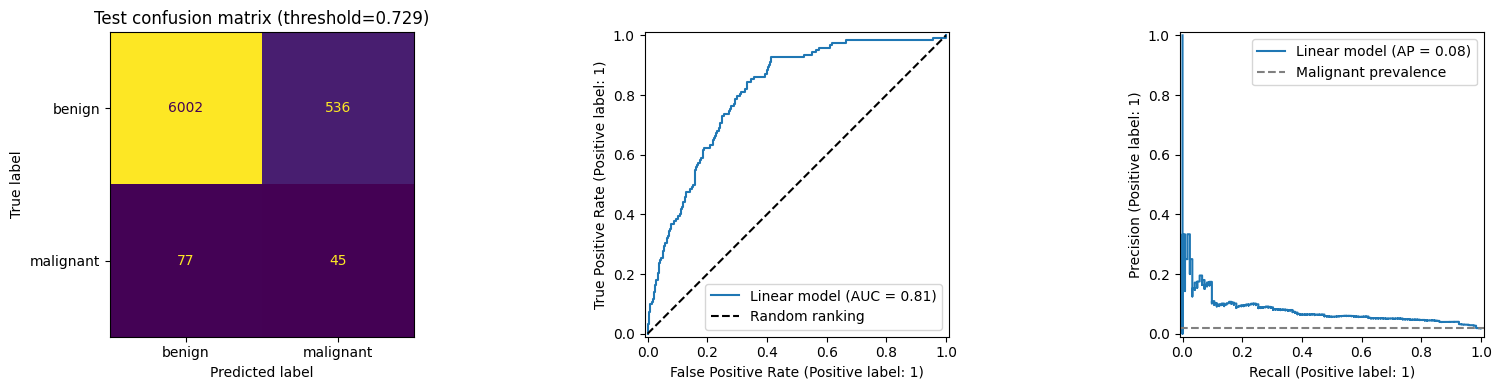

Saved model, metrics, patient splits, and test predictions in artifacts/.


In [ ]:
# Final evaluation: untouched test images compared with their GroundTruth targets.
test_probabilities = model.predict_proba(X[test_idx])[:, 1]
test_predictions = (test_probabilities >= threshold).astype(np.int64)
y_test = y[test_idx]

metrics = {
    'roc_auc': float(roc_auc_score(y_test, test_probabilities)),
    'average_precision': float(average_precision_score(y_test, test_probabilities)),
    'balanced_accuracy': float(balanced_accuracy_score(y_test, test_predictions)),
    'malignant_recall': float(recall_score(y_test, test_predictions, zero_division=0)),
    'accuracy': float((test_predictions == y_test).mean()),
    'always_benign_accuracy': float((y_test == 0).mean()),
    'random_ranking_average_precision': float(y_test.mean()),
}
display(pd.Series(metrics, name='held_out_test'))
print(classification_report(y_test, test_predictions, labels=[0, 1],
                            target_names=CLASS_NAMES, digits=3, zero_division=0))
print('Default threshold (0.5), for comparison:')
print(classification_report(y_test, (test_probabilities >= 0.5).astype(int),
                            labels=[0, 1], target_names=CLASS_NAMES, digits=3, zero_division=0))

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
ConfusionMatrixDisplay.from_predictions(y_test, test_predictions, labels=[0, 1],
                                       display_labels=CLASS_NAMES, ax=axes[0], colorbar=False)
axes[0].set_title(f'Test confusion matrix (threshold={threshold:.3f})')
RocCurveDisplay.from_predictions(y_test, test_probabilities, ax=axes[1], name='Linear model')
axes[1].plot([0, 1], [0, 1], 'k--', label='Random ranking')
axes[1].legend()
PrecisionRecallDisplay.from_predictions(y_test, test_probabilities, ax=axes[2], name='Linear model')
axes[2].axhline(y_test.mean(), color='gray', linestyle='--', label='Malignant prevalence')
axes[2].legend()
plt.tight_layout()
plt.show()

results = labels.iloc[test_idx][['image_name', 'patient_id', 'benign_malignant', 'target']].copy()
results['malignant_score'] = test_probabilities
results['predicted_target'] = test_predictions
results['predicted_label'] = np.array(CLASS_NAMES)[test_predictions]
results['correct'] = results['target'] == results['predicted_target']
results.to_csv(ARTIFACTS / 'test_predictions.csv', index=False)
with (ARTIFACTS / 'test_metrics.json').open('w') as file:
    json.dump({'threshold': threshold, 'test_images': len(test_idx), **metrics}, file, indent=2)
joblib.dump({'model': model, 'threshold': threshold, 'image_size': IMAGE_SIZE,
             'class_names': CLASS_NAMES, 'feature_description': 'RGB pixels / 255, flattened'},
            ARTIFACTS / 'linear_melanoma_model.joblib')
print('Saved model, metrics, patient splits, and test predictions in artifacts/.')

{'image': 'ISIC_0074542', 'prediction': 'benign', 'malignant_score': 0.13638065849500336, 'threshold': 0.729063158100533}
GroundTruth: benign


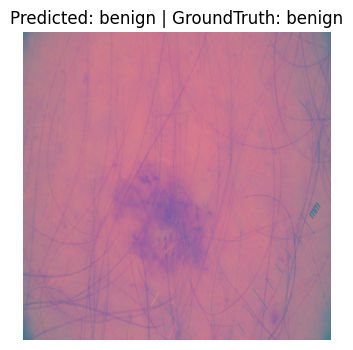

In [ ]:
def predict_image(path):
    """Return a benign/malignant prediction for a DICOM image using this fitted model."""
    feature = image_features(Path(path)).reshape(1, -1)
    score = float(model.predict_proba(feature)[0, 1])
    return {'image': Path(path).stem, 'prediction': CLASS_NAMES[int(score >= threshold)],
            'malignant_score': score, 'threshold': threshold}


# Demonstrate inference on a held-out image, then verify against GroundTruth.
example = labels.iloc[test_idx[0]]
prediction = predict_image(example['path'])
print(prediction)
print('GroundTruth:', example['benign_malignant'])
plt.figure(figsize=(5, 4))
plt.imshow(read_rgb_image(example['path']).resize((512, 512)))
plt.title(f"Predicted: {prediction['prediction']} | GroundTruth: {example['benign_malignant']}")
plt.axis('off')
plt.show()

# For another image, call predict_image(ROOT / 'train' / '<image_name>.dcm').
# Scores from a class-weighted model are NOT calibrated clinical probabilities.
# Only load joblib files you trust; they can execute code during loading.